# Módulos estándar · `random`

Generar valores aleatorios con `random` y `string`.

## 1. Identificador aleatorio

Escribir `random_user_id`, que genere un identificador aleatorio de 6 caracteres (letras y dígitos).

In [1]:
import random
import string

CARACTERES = string.ascii_letters + string.digits

def random_user_id(longitud=6):
    return "".join(random.choices(CARACTERES, k=longitud))

print(random_user_id())

sDWKJG


## 2. Identificadores a medida

Escribir `user_id_gen_by_user`, que pida el número de caracteres y cuántos identificadores generar, y los muestre uno por línea.

In [2]:
def user_id_gen_by_user():
    longitud = int(input("Número de caracteres: "))
    cantidad = int(input("Número de identificadores: "))
    for _ in range(cantidad):
        print(random_user_id(longitud))

user_id_gen_by_user()

Número de caracteres: 5
Número de identificadores: 3
4aiFu
QF8wh
QwrqJ


## 3. Colores aleatorios

Escribir `rgb_color_gen` (un color `rgb(r,g,b)`), `list_of_hexa_colors(n)` y `list_of_rgb_colors(n)`, y `generate_colors(tipo, n)`, que genere `n` colores `'hexa'` o `'rgb'`.

In [3]:
def rgb_color_gen():
    return "rgb({},{},{})".format(*(random.randint(0, 255) for _ in range(3)))

def list_of_hexa_colors(n):
    return [f"#{random.randint(0, 0xFFFFFF):06x}" for _ in range(n)]

def list_of_rgb_colors(n):
    return [rgb_color_gen() for _ in range(n)]

def generate_colors(tipo, n):
    return list_of_hexa_colors(n) if tipo == "hexa" else list_of_rgb_colors(n)

print(rgb_color_gen())
print(generate_colors("hexa", 3), generate_colors("rgb", 2))

rgb(229,221,24)
['#f531c6', '#befa5f', '#cb0584'] ['rgb(145,154,214)', 'rgb(37,160,175)']


## 4. Barajar y números únicos

Escribir `shuffle_list`, que devuelva una copia barajada de una lista, y una función que devuelva siete números aleatorios distintos entre 0 y 9.

In [4]:
def shuffle_list(lista):
    return random.sample(lista, len(lista))

def siete_unicos():
    return random.sample(range(10), 7)

print(shuffle_list([1, 2, 3, 4, 5]), siete_unicos())

[3, 2, 1, 4, 5] [7, 8, 3, 5, 9, 6, 4]


## 5. Semilla reproducible

Comprobar que `random.seed` hace que la secuencia se repita y que un generador `random.Random` propio no altera la secuencia del generador global.

In [5]:
random.seed(42)
primera = [random.randint(1, 100) for _ in range(5)]
random.seed(42)
segunda = [random.randint(1, 100) for _ in range(5)]
print(primera, segunda)
assert primera == segunda

propio = random.Random(7)
random.seed(42)
print(propio.choice("abcdef"), propio.random())
assert [random.randint(1, 100) for _ in range(5)] == primera

[82, 15, 4, 95, 36] [82, 15, 4, 95, 36]
c 0.9478653606090632


## 6. Elecciones con pesos

Elegir un elemento con `choice` y simular 10 000 tiradas de una ruleta con `choices` y pesos 70/20/10, comprobando que las frecuencias se acercan a los pesos.

In [6]:
from collections import Counter

random.seed(1)
print(random.choice(["piedra", "papel", "tijera"]))

premios = ["nada", "reintegro", "premio"]
pesos = [70, 20, 10]
tiradas = Counter(random.choices(premios, weights=pesos, k=10_000))
for premio, peso in zip(premios, pesos):
    frecuencia = tiradas[premio] / 10_000
    print(f"{premio:>9}: {frecuencia:.3f} (esperado {peso / 100:.2f})")
    assert abs(frecuencia - peso / 100) < 0.02

piedra
     nada: 0.697 (esperado 0.70)
reintegro: 0.204 (esperado 0.20)
   premio: 0.099 (esperado 0.10)


## 7. `sample` frente a `shuffle`

Sacar una combinación de 6 números distintos del 1 al 49 con `sample` y barajar una lista en su sitio con `shuffle`, comprobando que conserva los mismos elementos.

In [7]:
random.seed(3)
combinacion = sorted(random.sample(range(1, 50), 6))
print("Combinación:", combinacion)
assert len(set(combinacion)) == 6 and all(1 <= n <= 49 for n in combinacion)

lista = list(range(10))
random.shuffle(lista)
print("Barajada:", lista)
assert sorted(lista) == list(range(10))

Combinación: [9, 16, 24, 35, 38, 39]
Barajada: [4, 5, 9, 8, 2, 3, 6, 0, 1, 7]


## 8. `uniform` y `gauss`

Generar 10 000 valores con `uniform(0, 10)` y con `gauss(170, 8)` (alturas en cm), comparar su media y desviación con las teóricas y dibujar el histograma de las alturas.

uniform: media 5.02 (5), desviación 2.88 (2.89)
gauss:   media 169.96 (170), desviación 7.98 (8)


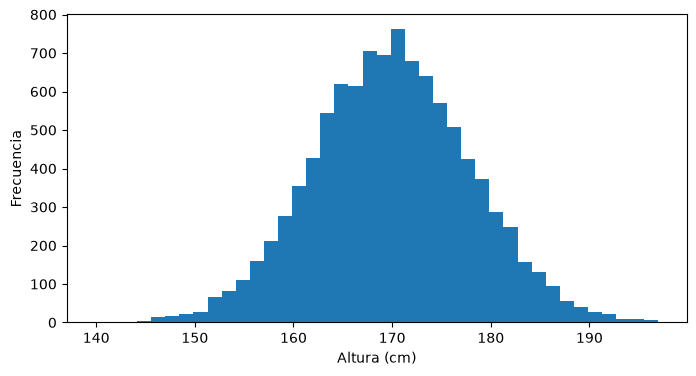

In [8]:
import statistics
import matplotlib.pyplot as plt

random.seed(5)
uniformes = [random.uniform(0, 10) for _ in range(10_000)]
alturas = [random.gauss(170, 8) for _ in range(10_000)]

print(f"uniform: media {statistics.mean(uniformes):.2f} (5), desviación {statistics.stdev(uniformes):.2f} ({10 / 12 ** 0.5:.2f})")
print(f"gauss:   media {statistics.mean(alturas):.2f} (170), desviación {statistics.stdev(alturas):.2f} (8)")
assert all(0 <= x <= 10 for x in uniformes)
assert abs(statistics.mean(alturas) - 170) < 0.5 and abs(statistics.stdev(alturas) - 8) < 0.3

fig, eje = plt.subplots(figsize=(8, 4))
eje.hist(alturas, bins=40)
eje.set_xlabel("Altura (cm)")
eje.set_ylabel("Frecuencia")
plt.show()

## 9. Dos dados

Simular 36 000 lanzamientos de dos dados y comparar la frecuencia de cada suma con su probabilidad teórica, obtenida contando las 36 combinaciones posibles.

In [9]:
from itertools import product

random.seed(6)
N = 36_000
sumas = Counter(random.randint(1, 6) + random.randint(1, 6) for _ in range(N))
teoricas = Counter(a + b for a, b in product(range(1, 7), repeat=2))

for suma in range(2, 13):
    print(f"{suma:>2}: {sumas[suma] / N:.4f}  teórica {teoricas[suma] / 36:.4f}")
    assert abs(sumas[suma] / N - teoricas[suma] / 36) < 0.01

 2: 0.0268  teórica 0.0278
 3: 0.0561  teórica 0.0556
 4: 0.0830  teórica 0.0833
 5: 0.1089  teórica 0.1111
 6: 0.1399  teórica 0.1389
 7: 0.1653  teórica 0.1667
 8: 0.1418  teórica 0.1389
 9: 0.1157  teórica 0.1111
10: 0.0811  teórica 0.0833
11: 0.0539  teórica 0.0556
12: 0.0274  teórica 0.0278


## 10. Contraseñas con `secrets`

Escribir `generar_contraseña(longitud)` con `secrets`, que incluya al menos una minúscula, una mayúscula, un dígito y un símbolo, y mostrar por qué `random` no sirve para esto: con la misma semilla se repite la contraseña.

In [10]:
import secrets

SIMBOLOS = "!@#$%&*?-_"
GRUPOS = [string.ascii_lowercase, string.ascii_uppercase, string.digits, SIMBOLOS]

def generar_contraseña(longitud=12, rng=secrets.SystemRandom()):
    caracteres = [rng.choice(grupo) for grupo in GRUPOS]
    caracteres += rng.choices("".join(GRUPOS), k=longitud - len(GRUPOS))
    rng.shuffle(caracteres)
    return "".join(caracteres)

def es_robusta(clave):
    return all(any(c in grupo for c in clave) for grupo in GRUPOS)

claves = [generar_contraseña(16) for _ in range(1000)]
assert all(len(c) == 16 and es_robusta(c) for c in claves)
print("1000 contraseñas válidas de 16 caracteres; un token_urlsafe(16) tiene", len(secrets.token_urlsafe(16)), "caracteres")

# Quien conozca la semilla de random puede reproducir la contraseña
a = generar_contraseña(12, random.Random(2026))
b = generar_contraseña(12, random.Random(2026))
print(a, b, a == b)
assert a == b

1000 contraseñas válidas de 16 caracteres; un token_urlsafe(16) tiene 22 caracteres
SK@8*PUd-8E# SK@8*PUd-8E# True


## 11. Paseo aleatorio

Simular un paseo aleatorio de 1000 pasos de ±1, dibujarlo y comprobar con 2000 paseos que la media del cuadrado de la posición final se acerca al número de pasos.

Posición final: 14 · máxima distancia al origen: 21


Media de x²: 975 (esperado 1000)


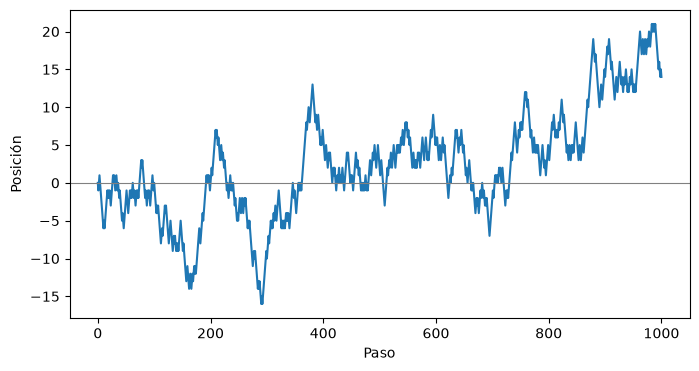

In [11]:
def paseo(pasos):
    posiciones = [0]
    for _ in range(pasos):
        posiciones.append(posiciones[-1] + random.choice((-1, 1)))
    return posiciones

random.seed(8)
camino = paseo(1000)
print("Posición final:", camino[-1], "· máxima distancia al origen:", max(map(abs, camino)))

finales = [paseo(1000)[-1] for _ in range(2000)]
media_cuadrados = statistics.mean(x * x for x in finales)
print(f"Media de x²: {media_cuadrados:.0f} (esperado 1000)")
assert abs(media_cuadrados - 1000) < 100

fig, eje = plt.subplots(figsize=(8, 4))
eje.plot(camino)
eje.axhline(0, color="gray", linewidth=0.8)
eje.set_xlabel("Paso")
eje.set_ylabel("Posición")
plt.show()

## 12. Baraja española

Crear la baraja española de 40 cartas, barajarla y repartir una a una 10 cartas a cada uno de 4 jugadores, comprobando que no se repite ni se pierde ninguna.

In [12]:
PALOS = ["oros", "copas", "espadas", "bastos"]
FIGURAS = ["as", "2", "3", "4", "5", "6", "7", "sota", "caballo", "rey"]

def nueva_baraja():
    return [f"{figura} de {palo}" for palo in PALOS for figura in FIGURAS]

def repartir(baraja, jugadores, cartas):
    return [baraja[i::jugadores][:cartas] for i in range(jugadores)]

random.seed(40)
baraja = nueva_baraja()
random.shuffle(baraja)
manos = repartir(baraja, 4, 10)
for i, mano in enumerate(manos, 1):
    print(f"Jugador {i}: {', '.join(mano)}")

repartidas = [carta for mano in manos for carta in mano]
assert len(repartidas) == 40 and set(repartidas) == set(nueva_baraja())

Jugador 1: 4 de oros, 3 de copas, 5 de bastos, 5 de espadas, 6 de oros, as de espadas, 7 de copas, 4 de espadas, caballo de oros, 3 de oros
Jugador 2: sota de oros, 2 de copas, 6 de bastos, 2 de bastos, 2 de espadas, 2 de oros, as de oros, caballo de espadas, 4 de copas, 4 de bastos
Jugador 3: caballo de bastos, 6 de espadas, as de bastos, sota de copas, sota de espadas, 5 de oros, 7 de espadas, 3 de bastos, caballo de copas, sota de bastos
Jugador 4: rey de oros, rey de copas, 7 de bastos, as de copas, 7 de oros, rey de bastos, 5 de copas, 3 de espadas, 6 de copas, rey de espadas
